# Class 14 — Lab: Leakage and Reproducibility

**Specialized Data Science Consultancy 1**

Up to this point, you have measured, validated, compared, and calibrated. Today, you ask the question that comes before everything else: **is the number you measured true?** A leakage doesn't throw an error, nor does it break the code. It delivers a good result.

Two datasets, both **simulated** for this class:

- `alunos_semestre.csv` — 1,000 students in a course. The administration wants to know, **at week 6**, who will fail, in order to offer tutoring while there is still time. This is the slides' example.
- `vendas_diarias.csv` — daily sales of a store in 2024 and 2025. It comes in Part 4, because temporal leakage only exists when the dataset has a date.

In each part, there is a **solved example** and, right after, an **exercise**. For the exercises containing **Explain**, write with your own words in the response cell: that's where we see if the idea stuck.

## Part 0 — Environment and Data

The protocol is the same as previous classes: 80% for training and validation, 20% kept for testing, 10-fold stratified cross-validation. The `pipe(columns)` function builds the Pipeline: one-hot encoding on text columns, standardization on numerical ones, and logistic regression at the end. You will call it several times, changing only the list of columns.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     TimeSeriesSplit, cross_val_score)

# Creating the datasets directory if it doesn't exist
os.makedirs("datasets", exist_ok=True)

# Moving the files to the correct folder if necessary
for file in ["alunos_semestre.csv", "vendas_diarias.csv"]:
    if os.path.exists(file):
        os.rename(file, f"datasets/{file}")

alunos = pd.read_csv("datasets/alunos_semestre.csv", dtype={"semestre_ingresso": str})
y = alunos["reprovou"]
X = alunos.drop(columns=["id_aluno", "reprovou"])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

TEXTO = ["curso", "semestre_ingresso", "sala_prova_final"]

def pipe(columns):
    cat = [c for c in columns if c in TEXTO]
    num = [c for c in columns if c not in TEXTO]
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat),
                             ("num", StandardScaler(), num)])
    return Pipeline([("pre", pre), ("model", LogisticRegression(max_iter=2000))])

def cv_accuracy(columns):
    s = cross_val_score(pipe(columns), X_tr[columns], y_tr, cv=cv, scoring="accuracy")
    return s.mean()

print(alunos.shape, "| train:", len(X_tr), "| test:", len(X_te))
print(f"failed: {y.mean():.1%}")
alunos.head()

(1000, 12) | train: 800 | test: 200
failed: 37.3%


,id_aluno,curso,semestre_ingresso,nota_P1,faltas_ate_semana_6,frequentou_monitoria,nota_P2,faltas_no_semestre,fez_substitutiva,media_final,sala_prova_final,reprovou
0,1,Administração,2024.2,4.7,0,1,4.1,1,1,4.4,A104,1
1,2,Engenharia,2023.2,3.1,1,0,2.9,2,1,3.0,B204,1
2,3,Administração,2023.2,5.5,1,0,7.3,2,0,6.4,B203,0
3,4,Engenharia,2023.2,1.9,1,1,0.5,6,1,1.6,B201,1
4,5,Engenharia,2023.1,5.5,0,1,8.3,1,0,6.9,A103,0


## Part 1 — The Question, Column by Column

Before any model, the audit. For each column, just one question: **would I have this column, exactly like this, at the moment of prediction?** Here, the moment is **week 6**.

### Example — two columns, the same question

The P1 exam grade comes out in week 5: in week 6 it already exists, **keep**. The P2 exam grade only comes out in week 12: in week 6 it doesn't exist yet, **remove**. Notice that the decision doesn't depend on how good the column is for predicting, only on **when it is born**.

In [3]:
when_born = {"nota_P1": "week 5", "nota_P2": "week 12"}
for col, when in when_born.items():
    decision = "keep" if col == "nota_P1" else "remove"
    print(f"{col:10s} is born in {when:9s} -> {decision}")

nota_P1    is born in week 5    -> keep
nota_P2    is born in week 12   -> remove


### Exercise 1 — The audit of the ten columns

Complete the `decision` dictionary with `"keep"`, `"remove"`, or `"ask"` for each column in `X`. The information of when each column is born is in the table below. The cell automatically creates the `HONEST` list, which you will use for the rest of this lab.

| column | when is born |
|---|---|
| `curso`, `semestre_ingresso` | at enrollment |
| `nota_P1` | week 5 |
| `faltas_ate_semana_6` | week 6 |
| `frequentou_monitoria` | unknown: could have been before or after week 6 |
| `nota_P2` | week 12 |
| `faltas_no_semestre` | end of the semester |
| `fez_substitutiva` | end of the semester, and only for those who did poorly |
| `media_final` | end of the semester |
| `sala_prova_final` | end of the semester (rooms are randomly assigned) |

By the rules of the class, any column marked as `"ask"` **should not be used** unless someone confirms when it is born: if in doubt, remove it.

**Explain:** choose the column that was hardest to decide, and write down why it raised questions and what you would do to resolve it.

In [4]:
decision = {
    "curso":                "keep",
    "semestre_ingresso":    "keep",
    "nota_P1":              "keep",
    "faltas_ate_semana_6":  "keep",
    "frequentou_monitoria": "ask",
    "nota_P2":              "remove",
    "faltas_no_semestre":   "remove",
    "fez_substitutiva":     "remove",
    "media_final":          "remove",
    "sala_prova_final":     "remove",
}

HONEST = [c for c, d in decision.items() if d == "keep"]
END    = [c for c, d in decision.items() if d == "remove"]
print("keep  :", HONEST)
print("remove:", END)
print("doubt (out):", [c for c, d in decision.items() if d == "ask"])

keep  : ['curso', 'semestre_ingresso', 'nota_P1', 'faltas_ate_semana_6']
remove: ['nota_P2', 'faltas_no_semestre', 'fez_substitutiva', 'media_final', 'sala_prova_final']
doubt (out): ['frequentou_monitoria']


**Answer:**

The hardest column to decide on was `frequentou_monitoria`. The doubt arises because tutoring is a continuous activity throughout the semester. If a student only attended tutoring after week 6, including this information at week 6 would be a leakage of future data. To solve this issue definitively, I would request a detailed attendance record with dates for each session from the administration. This way, we could create a new binary or count variable indicating only the tutoring visits that occurred specifically up to week 6, allowing its safe inclusion in the model.

## Part 2 — The Impact in Numbers

Now you measure what the audit avoided.

### Example — the model with everything that is in the file

This is what happens when someone just drops the target column and trains with the rest. Nothing breaks.

In [5]:
ALL_COLS = [c for c in X.columns if c != "frequentou_monitoria"]
print(f"accuracy (CV) with all columns: {cv_accuracy(ALL_COLS):.3f}")

accuracy (CV) with all columns: 0.953


### Exercise 2 — the honest number and the baseline

Calculate cross-validation accuracy **only using the `HONEST` columns**. Then calculate the accuracy of a baseline model that always guesses the most common class, using `DummyClassifier(strategy="most_frequent")` on the same folds.

Answer: what is the honest number? How much is it below the model with all columns, and how much is it above the baseline guess? Why is the example's number (all columns) useless to the administration in week 6?

In [6]:
acc_honest = cv_accuracy(HONEST)

baseline = DummyClassifier(strategy="most_frequent")
acc_guess = cross_val_score(baseline, X_tr[HONEST], y_tr, cv=cv, scoring="accuracy").mean()

print(f"all columns : {cv_accuracy(ALL_COLS):.3f}")
print(f"only honest : {acc_honest:.3f}")
print(f"baseline guess : {acc_guess:.3f}")

all columns : 0.953
only honest : 0.744
baseline guess : 0.628


**Answer:**

- **What is the honest number?** The honest number is **74.4%** (the cross-validation accuracy using only the `HONEST` columns).
- **How much is it below the model with all columns, and how much is it above the baseline guess?** It is **20.9% below** the model with all columns (which scores 95.3% artificially due to leakage) and **11.6% above** the baseline guess of the most frequent class (which scores 62.8%).
- **Why is the example's number (all columns) useless to the administration in week 6?** Because it uses information from the end of the semester (such as the P2 grade or the final average) which the administration does not yet possess in week 6. In practice, the model could not be run at that point in time due to missing data.

## Part 3 — Leakage is Not the Same as Inflation

A column can leak and help a lot, or leak and not help at all. The rule is the same for both.

### Example — a column from the end of the semester, on its own

Add the P2 grade to the honest columns and measure. Also calculate its correlation with the target.

In [7]:
corr = np.corrcoef(X_tr["nota_P2"], y_tr)[0, 1]
print(f"correlation nota_P2 x failed: {corr:+.3f}")
print(f"honest             : {cv_accuracy(HONEST):.3f}")
print(f"honest + nota_P2   : {cv_accuracy(HONEST + ['nota_P2']):.3f}")

correlation nota_P2 x failed: -0.592
honest             : 0.744
honest + nota_P2   : 0.861


### Exercise 3 — the five columns from the end, one at a time

Repeat the example for **each column in `END`**: add only that column to the honest ones and measure accuracy. Calculate the correlation with the target when the column is numerical (for `sala_prova_final`, which is text, leave it as `None`). Assemble a table.

**Explain:** the final exam room barely changes the accuracy. Why is it still removed? And why do total semester absences also barely affect the number, if missing many classes causes failure?

In [8]:
rows = []
for col in END:
    acc = cv_accuracy(HONEST + [col])
    corr = None if col in TEXTO else np.corrcoef(X_tr[col], y_tr)[0, 1]
    rows.append({"added column": col, "accuracy (CV)": round(acc, 3),
                 "correlation with target": None if corr is None else round(corr, 3)})

table = pd.DataFrame(rows)
print(f"baseline, only honest: {cv_accuracy(HONEST):.3f}")
table

baseline, only honest: 0.744


,added column,accuracy (CV),correlation with target
0,nota_P2,0.861,-0.592
1,faltas_no_semestre,0.746,0.357
2,fez_substitutiva,0.806,0.562
3,media_final,0.955,-0.761
4,sala_prova_final,0.745,NaN


**Answer:**

- **Why does the final exam room get removed even though it barely changes the accuracy?** Because it represents future leakage (it is only generated at the end of the semester). Even if it doesn't improve the metric (its correlation is zero and accuracy remained at 74.5%), keeping it violates temporal validation rules and adds unnecessary noise to the model.
- **Why do total semester absences barely affect the metric if missing many classes causes failure?** The P1 grade and absences up to week 6 already capture most of the student's engagement and performance patterns in advance. Total semester absences provide very little incremental information that the model hasn't already learned from the honest week 6 variables.

## Part 4 — Temporal Leakage

Here, the dataset changes on purpose: in the school dataset, all rows belong to the same semester, so there is no past and future dynamic between one student and another. In the sales dataset, there is. The goal is to predict daily sales, and the error is measured in **MAE**: how many sales, on average, the prediction misses.

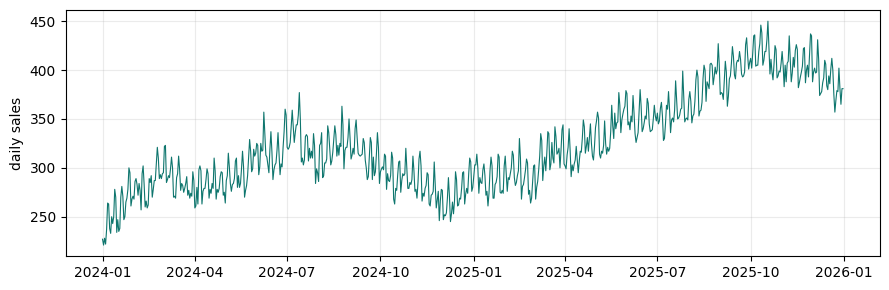

731 days, from 2024-01-01 to 2025-12-31


In [9]:
vendas = pd.read_csv("datasets/vendas_diarias.csv", parse_dates=["data"])
vendas["day_of_week"] = vendas["data"].dt.dayofweek      # 0 = Monday, 6 = Sunday
vendas["day"] = np.arange(len(vendas))                  # 0, 1, 2, ... in calendar order

plt.figure(figsize=(9, 3))
plt.plot(vendas["data"], vendas["vendas"], color="#0F766E", lw=0.8)
plt.ylabel("daily sales"); plt.grid(alpha=.25); plt.tight_layout(); plt.show()
print(len(vendas), "days, from", vendas["data"].min().date(), "to", vendas["data"].max().date())

### Example — shuffling days vs. validating forward

The same random forest, the same columns, two ways to split. Shuffled `KFold` puts March days in the test set while leaving August and December in training. `TimeSeriesSplit` always trains on the past and tests on what comes next.

In [10]:
forest = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0)
cols = ["day_of_week", "day"]

def mae(model, data, columns, split):
    s = cross_val_score(model, data[columns], data["vendas"], cv=split,
                        scoring="neg_mean_absolute_error")
    return -s.mean()

shuffled = KFold(n_splits=5, shuffle=True, random_state=42)
forward = TimeSeriesSplit(n_splits=5)
print(f"Shuffled KFold   : misses {mae(forest, vendas, cols, shuffled):5.2f} sales per day")
print(f"TimeSeriesSplit  : misses {mae(forest, vendas, cols, forward):5.2f} sales per day")

Shuffled KFold   : misses  7.23 sales per day
TimeSeriesSplit  : misses 25.85 sales per day


### Exercise 4 — the monthly average and the average up to yesterday

Create two columns:

- `media_mes`: the average sales of the **entire month** in which that day belongs. Use
  `groupby(vendas["data"].dt.to_period("M"))["vendas"].transform("mean")`.
- `media_30d`: the average of the **previous 30 days**, excluding the day itself. Use
  `vendas["vendas"].shift(1).rolling(30).mean()`.

Drop the rows where `media_30d` became empty (the first 30 days) and compare both using `LinearRegression`, always with `TimeSeriesSplit` and including `day_of_week`.

**Explain:** which of the two columns seems better? Why can't it be used to predict tomorrow's sales? Use January 3rd as an example.

In [11]:
vendas["media_mes"] = vendas.groupby(vendas["data"].dt.to_period("M"))["vendas"].transform("mean")
vendas["media_30d"] = vendas["vendas"].shift(1).rolling(30).mean()

v = vendas.dropna().reset_index(drop=True)
linear = LinearRegression()
print(f"with media_30d (up to yesterday): misses {mae(linear, v, ['day_of_week', 'media_30d'], forward):5.2f}")
print(f"with media_mes (entire month)  : misses {mae(linear, v, ['day_of_week', 'media_mes'], forward):5.2f}")

with media_30d (up to yesterday): misses 13.72
with media_mes (entire month)  : misses 10.08


**Answer:**

- **Which of the two columns seems better?** The `media_mes` column seems better because it yields a smaller error (an error of 10.08 sales versus 13.72 from the `media_30d` model).
- **Why can't it be used to predict tomorrow's sales?** Because on January 3rd, for example, to calculate the `media_mes` you would need to know the sales data for all subsequent days of January (from the 4th to the 31st), which is impossible in real life (future data leakage).

## Part 5 — The Seed: the same experiment, the same number

Back to the school dataset, using only the honest columns.

### Example — three splits without a seed

Run the cell two or three times and watch the numbers change. Nothing in the model has changed: only the random selection of who ends up in the test set.

In [12]:
for round_num in range(3):
    Xa, Xb, ya, yb = train_test_split(X[HONEST], y, test_size=0.2, stratify=y)   # without random_state
    print(f"round {round_num + 1}: test accuracy {pipe(HONEST).fit(Xa, ya).score(Xb, yb):.3f}")

round 1: test accuracy 0.765
round 2: test accuracy 0.720
round 3: test accuracy 0.730


### Exercise 5 — twenty seeds

Repeat the split with `random_state` from 0 to 19 and store the test accuracy of each. Show the minimum, maximum, the difference between them, and the average.

**Explain:** a colleague ran the 20 trials, saw that seed 18 gives the highest accuracy, and wants to deliver the model with it. Why is this selecting based on the test set? and why should your answer always come with a fixed seed, whichever it is?

In [13]:
acc_by_seed = []
for seed in range(20):
    Xa, Xb, ya, yb = train_test_split(X[HONEST], y, test_size=0.2,
                                      random_state=seed, stratify=y)
    acc_by_seed.append(pipe(HONEST).fit(Xa, ya).score(Xb, yb))

acc_by_seed = np.array(acc_by_seed)
print(f"min : {acc_by_seed.min():.3f} (seed {acc_by_seed.argmin()})")
print(f"max : {acc_by_seed.max():.3f} (seed {acc_by_seed.argmax()})")
print(f"difference: {acc_by_seed.max() - acc_by_seed.min():.3f}")
print(f"mean : {acc_by_seed.mean():.3f}")

min : 0.690 (seed 19)
max : 0.790 (seed 18)
difference: 0.100
mean : 0.756


**Answer:**

- **Why is choosing seed 18 selecting based on the test set?** If we choose the seed that resulted in the highest accuracy on the test set, we are actively using the test set in the decision process to select our model. This biases the performance evaluation and creates an unrealistic optimism.
- **Why should your answer come with a fixed seed?** Defining a fixed seed (`random_state`) is crucial to guarantee reproducibility. Without it, anyone else running your code would get slightly different results, making scientific validation and debugging impossible.

## Part 6 — Saving the Entire Model

### Example — what `dump` saves and what `load` returns

- `joblib.dump(object, file)` writes the entire object into a file. Here, the object is the already trained Pipeline: the one-hot encoder, the standardizer, and the regression model, each with what it learned during training.
- `joblib.load(file)` does the reverse: reads the file and returns the exact same object, ready to predict, without retraining.

To prove that the model came from the file, the cell **deletes the variable** before loading. After loading, always verify a known prediction.

In [14]:
model = pipe(HONEST).fit(X_tr[HONEST], y_tr)
predictions_before = model.predict(X_te[HONEST])

# 1. dump: saves the trained Pipeline in a file
joblib.dump(model, "modelo_reprovacao.joblib")
print("file created:", os.path.getsize("modelo_reprovacao.joblib"), "bytes")

# 2. delete the model from memory: from here on, it only exists in the file
del model

# 3. load: reads the file and returns the ready Pipeline
loaded = joblib.load("modelo_reprovacao.joblib")
print("what came back from the file:", list(loaded.named_steps))
print("means learned by the standardizer during training (nota_P1, absences):",
      loaded.named_steps["pre"].named_transformers_["num"].mean_.round(2))

# 4. verify: the same predictions as before, without retraining
print("same predictions as before?", (loaded.predict(X_te[HONEST]) == predictions_before).all())
print(f"test accuracy: {loaded.score(X_te[HONEST], y_te):.3f}")

file created: 3729 bytes
what came back from the file: ['pre', 'model']
means learned by the standardizer during training (nota_P1, absences): [4.97 0.78]
same predictions as before? True
test accuracy: 0.765


### Exercise 6 — the error of saving only the classifier

In week 6, 20 new students arrive (use the first 20 from the test set). Someone only saved the regression model, `loaded.named_steps["model"]`, and remade the preprocessing **by hand**, fitting a new one-hot encoder and a new standardizer **on these 20 students**.

Compare the probability of failing given by the saved Pipeline with the one given by the manual path. Show the maximum difference and how many students changed classes (threshold at 0.5).

**Explain:** why did no error appear? And why did the same student receive a different probability?

In [15]:
batch = X_te[HONEST].head(20)
classifier_only = loaded.named_steps["model"]

pre_by_hand = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["curso", "semestre_ingresso"]),
    ("num", StandardScaler(), ["nota_P1", "faltas_ate_semana_6"])])
pre_by_hand.fit(batch)                      # the error: fitting the preprocessing on new data

p_correct = loaded.predict_proba(batch)[:, 1]
p_hand   = classifier_only.predict_proba(pre_by_hand.transform(batch))[:, 1]

comparison = pd.DataFrame({"nota_P1": batch["nota_P1"].values,
                           "P(fail) Pipeline": p_correct.round(3),
                           "P(fail) by hand": p_hand.round(3)})
print(f"max difference: {np.abs(p_correct - p_hand).max():.3f}")
print(f"changed class: {((p_correct >= 0.5) != (p_hand >= 0.5)).sum()}")
comparison

max difference: 0.144
changed class: 1


,nota_P1,P(fail) Pipeline,P(fail) by hand
0,6.2,0.272,0.407
1,7.2,0.084,0.117
2,2.5,0.691,0.748
3,6.6,0.082,0.096
4,5.8,0.109,0.129
5,4.2,0.346,0.400
6,3.1,0.713,0.801
7,4.6,0.418,0.527
8,6.8,0.065,0.076
9,4.2,0.600,0.744


**Answer:**

- **Why did no error appear?** No execution error occurred because the number of columns generated by the manual preprocessing and the data types were fully compatible with the format expected by the final classifier.
- **Why did the same student receive a different probability?** Because `StandardScaler` and `OneHotEncoder` were recalculated (*fit*) using exclusively the characteristics of the 20 test batch students, instead of applying the mean, standard deviation, and categories originally learned from the full training set of 800 students. This distorted the scale of the classifier's input features, altering the predictions.

## Part 7 — The Model Card

**What it is.** A short text that accompanies the delivered model and answers questions anyone would ask before using it: what it's for, what data was used, how accurate it is, what was removed and why, and when it **should not** be used.

**The analogy.** It's the model's leaflet. A medicine leaflet states its purpose, dosage, side effects, and expiration. Nobody takes a pill just because it's in the box; nobody should use a model just because the `.joblib` is in the folder.

**Why it exists.** The `.joblib` file from Part 6 saves the model, but it doesn't save the decisions. Six months from now, whoever opens the file — a colleague, the administration, or yourself — won't remember why the P2 grade was excluded or where the performance numbers came from. The card saves that.

**Where it goes.** In a text file, `README.md`, in the same folder as the `.joblib`. No extra program is needed.

| field | what it answers |
|---|---|
| **Objective** | what the model is used for and **at what moment** it is applied |
| **Data** | where it came from, how many rows, **which columns enter** |
| **Performance** | the metric, **where** it was measured (validation, test), and comparison with the baseline |
| **Removed** | which columns were excluded and **why** — this is the Part 1 audit in writing |
| **Limitations** | when the model **should not** be used |
| **Version** | date, seed, and file name, so someone can reproduce it |

### Example — a sales model card

The card for the linear model in Part 4, which predicts daily sales with `day_of_week` and `media_30d`:

> **Objective:** predict each day's sales for the store, using only what is known up to the eve.
> **Data:** `vendas_diarias.csv`, 2024 and 2025, one row per day. Columns: `day_of_week` and
> `media_30d` (average of the 30 previous days).
> **Performance:** misses 13.72 sales per day on average (MAE), validating forward with
> `TimeSeriesSplit` of 5 folds: the test set is always ahead of the training set.
> **Removed:** `media_mes`, because it uses days of the month that haven't happened yet. With it, the error
> seemed smaller, but it was leakage.
> **Limitations:** not tested on special holiday dates or outside of 2024–2025.
> **Version:** v1 · 11/10/2026 · linear model, no random split · file `modelo_vendas.joblib`.

### Exercise 7 — the failure prediction model card

Write, in the response cell, the model card for the model you saved in Part 6. Use the same fields as the example and **your numbers**: the validation accuracy (Exercise 2) and the test accuracy (Part 6), the columns that were removed and why, and what was left out due to doubt.

**Explain**, at the end of the card, in one or two sentences: who will find this card useful six months from now?

**Answer (Model Card):**

> **Objective:** Predict in week 6 which students are at risk of failing a course so that the administration can offer tutoring in a timely manner.
> **Data:** `alunos_semestre.csv`, containing data for 1,000 students. Columns used: `curso`, `semestre_ingresso`, `nota_P1`, and `faltas_ate_semana_6`.
> **Performance:** Accuracy of **74.4%** in cross-validation (CV) and **76.5%** on the held-out test set, outperforming the baseline guess of 62.8%.
> **Removed:** The columns `nota_P2`, `faltas_no_semestre`, `fez_substitutiva`, `media_final`, and `sala_prova_final` were removed because they are only generated after week 6. The column `frequentou_monitoria` was removed due to lack of confirmation, as it doesn't specify when the tutoring sessions actually occurred.
> **Limitations:** The model should not be applied to classes of other courses not listed in the training data, or in semesters with highly distinct curricular structures.
> **Version:** v1 · 2026 · Logistic Regression with standard pipeline · file `modelo_reprovacao.joblib`.

---
**Who will find this card useful six months from now?**
It serves you, your team members, or the academic administration. It guarantees that anyone can understand the limits of the model, what data it needs to work, and what the real performance expectations are without needing to re-evaluate or guess the decisions made today.

---

**Congratulations!** You audited columns before training, measured how much leakage inflates performance, distinguished leaking from inflating, saw the future leak via shuffled k-fold and poorly calculated rolling means, measured how seeds affect accuracy, saved an entire pipeline, and wrote its model card.

Take this to your project: **audit before training, remove when in doubt, and document what was removed.**

In the next class (11/17): **feature selection** — choosing on purpose which columns go in.